<center><h1>Xia_Iris_HW4</h1></center>
<br>
<br>

Name: Iris Xia
<br>
Github Username: xd11997
<br>
USC ID: 1152659547

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Get the AReM Data Set

In [3]:
from pathlib import Path

data_dir = Path.cwd().parent / "HW3" / "AReM"
columns = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
all_data = {}

for file_path in sorted(data_dir.glob("*/*.csv")):
    activity = file_path.parent.name
    dataset_number = int(file_path.stem.removeprefix("dataset"))
    recording = pd.read_csv(
        file_path,
        sep=r",\s*|\s+",
        engine="python",
        comment="#",
        header=None,
        names=columns,
        usecols=range(len(columns)),
    )
    all_data[(activity, dataset_number)] = recording

print(f"Loaded {len(all_data)} recordings")

Loaded 88 recordings


### (b) Splitting Data

In [4]:
test_dataset_ids = {"bending1": {1, 2}, "bending2": {1, 2}}

train_data = {}
test_data = {}

for (activity, dataset_number), recording in all_data.items():
    if dataset_number in test_dataset_ids.get(activity, {1, 2, 3}):
        test_data[(activity, dataset_number)] = recording
    else:
        train_data[(activity, dataset_number)] = recording

print(f"Training files: {len(train_data)}")
print(f"Test files: {len(test_data)}")

Training files: 69
Test files: 19


### (c) Feature Extraction

#### i. Research

Time-domain features summarize a signal directly in the time domain. Common examples include:
- Central tendency and quantiles: mean, median, and quantiles such as Q1 and Q3
- Extrema and range: minimum, maximum, and range
- Variability: variance, standard deviation, interquartile range (IQR), and mean absolute deviation
- Distribution shape: skewness and kurtosis
- Amplitude and energy: root mean square (RMS) and signal energy (the sum of squared values)
- Temporal behavior: linear trend or slope, successive-value changes (such as mean absolute change), zero- or threshold-crossing rate, peak count, and autocorrelation at selected lags
Together, these features describe a signal’s typical level, spread, distribution shape, magnitude, and temporal behavior. For multichannel sensor data, they can be calculated separately for each channel in each recording. Frequency-domain measures, such as Fourier coefficients, belong to a different feature family and are not included here.

#### ii. Extraction

In [6]:
feature_rows = {}

for (activity, dataset_number), recording in all_data.items():
    row = {}
    sensor_columns = recording.columns[1:]

    for series_number, column in enumerate(sensor_columns, start=1):
        values = recording[column]
        row[f"minimum_{series_number}"] = values.min()
        row[f"maximum_{series_number}"] = values.max()
        row[f"mean_{series_number}"] = values.mean()
        row[f"median_{series_number}"] = values.median()
        row[f"standard_deviation_{series_number}"] = values.std(ddof=1)
        row[f"first_quartile_{series_number}"] = values.quantile(0.25)
        row[f"third_quartile_{series_number}"] = values.quantile(0.75)

    feature_rows[(activity, dataset_number)] = row

feature_table = pd.DataFrame.from_dict(feature_rows, orient="index")
feature_table.index = pd.MultiIndex.from_tuples(
    feature_table.index, names=["activity", "dataset"]
)

train_features = feature_table.loc[list(train_data)]
test_features = feature_table.loc[list(test_data)]
train_labels = pd.Series(
    train_features.index.get_level_values("activity"),
    index=train_features.index,
    name="activity",
)
test_labels = pd.Series(
    test_features.index.get_level_values("activity"),
    index=test_features.index,
    name="activity",
)

assert feature_table.shape == (88, 42)
assert train_features.shape == (69, 42)
assert test_features.shape == (19, 42)

print(f"All features: {feature_table.shape}")
print(f"Training features: {train_features.shape}")
print(f"Test features: {test_features.shape}")
feature_table.head()

All features: (88, 42)
Training features: (69, 42)
Test features: (19, 42)


minimum_1  maximum_1     mean_1  median_1  \
activity dataset                                              
bending1 1            37.25      45.00  40.624792     40.50   
         2            38.00      45.67  42.812812     42.50   
         3            35.00      47.40  43.954500     44.33   
         4            33.00      47.75  42.179812     43.50   
         5            33.00      45.75  41.678063     41.75   

                  standard_deviation_1  first_quartile_1  third_quartile_1  \
activity dataset                                                             
bending1 1                    1.476967             39.25             42.00   
         2                    1.435550             42.00             43.67   
         3                    1.558835             43.00             45.00   
         4                    3.670666             39.15             45.00   
         5                    2.243490             41.33             42.75   

                  minimum_2  maximum_2    mean_2  ...  standard_deviation_5  \
activity dataset                                  ...                         
bending1 1              0.0       1.30  0.358604  ...              2.188449   
         2              0.0       1.22  0.372437  ...              1.995255   
         3              0.0       1.70  0.426250  ...              1.999604   
         4              0.0       3.00  0.696042  ...              3.849448   
         5              0.0       2.83  0.535979  ...              2.411026   

                  first_quartile_5  third_quartile_5  minimum_6  maximum_6  \
activity dataset                                                             
bending1 1                 33.0000             36.00        0.0       1.92   
         2                 32.0000             34.50        0.0       3.11   
         3                 35.3625             36.50        0.0       1.79   
         4                 30.4575             36.33        0.0       2.18   
         5                 28.4575             31.25        0.0       1.79   

                    mean_6  median_6  standard_deviation_6  first_quartile_6  \
activity dataset                                                               
bending1 1        0.570583      0.43              0.582915               0.0   
         2        0.571083      0.43              0.601010               0.0   
         3        0.493292      0.43              0.513506               0.0   
         4        0.613521      0.50              0.524317               0.0   
         5        0.383292      0.43              0.389164               0.0   

                  third_quartile_6  
activity dataset                    
bending1 1                    1.30  
         2                    1.30  
         3                    0.94  
         4                    1.00  
         5                    0.50  

[5 rows x 42 columns]

#### iii. Standard Deviation

In [7]:
feature_values = feature_table.to_numpy(dtype=float)
n_instances, n_features = feature_values.shape
n_bootstrap = 10000

# Bootstrap instances (rows) with replacement and estimate each feature's std.
rng = np.random.default_rng(552)
bootstrap_indices = rng.integers(
    0, n_instances, size=(n_bootstrap, n_instances)
)
bootstrap_stds = np.std(feature_values[bootstrap_indices], axis=1, ddof=1)

standard_deviations = np.std(feature_values, axis=0, ddof=1)
ci_lower, ci_upper = np.percentile(bootstrap_stds, [5, 95], axis=0)

std_confidence_intervals = pd.DataFrame(
    {
        "standard_deviation": standard_deviations,
        "90%_CI_lower": ci_lower,
        "90%_CI_upper": ci_upper,
    },
    index=feature_table.columns,
)

assert std_confidence_intervals.shape == (42, 3)
print(f"Bootstrap resamples: {n_bootstrap}")
print(f"Features summarized: {len(std_confidence_intervals)}")
std_confidence_intervals

Bootstrap resamples: 10000
Features summarized: 42


,standard_deviation,90%_CI_lower,90%_CI_upper
minimum_1,9.569975,8.256874,10.741701
maximum_1,4.394362,3.367466,5.284951
mean_1,5.335718,4.702209,5.882310
median_1,5.440054,4.790514,5.992412
standard_deviation_1,1.772153,1.568752,1.948021
first_quartile_1,6.153590,5.573883,6.636206
third_quartile_1,5.138925,4.341653,5.850324
minimum_2,0.000000,0.000000,0.000000
maximum_2,5.062729,4.612622,5.407682
mean_2,1.574164,1.394270,1.706270


#### iv. Select Features

I select **mean, standard deviation, and maximum** for each of the six time series, giving 18 selected features per instance.

- **Mean** summarizes the typical signal level during a recording.
- **Standard deviation** measures within-recording variation, which can distinguish steady activities from more dynamic ones.
- **Maximum** captures peak signal intensity.

Together, these features represent the signal's level, variability, and peak behavior. I prefer them to minimum because the extracted minima for time series 2 and 4 are constant at zero across all 88 recordings, so those minimum features provide no separation between instances.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

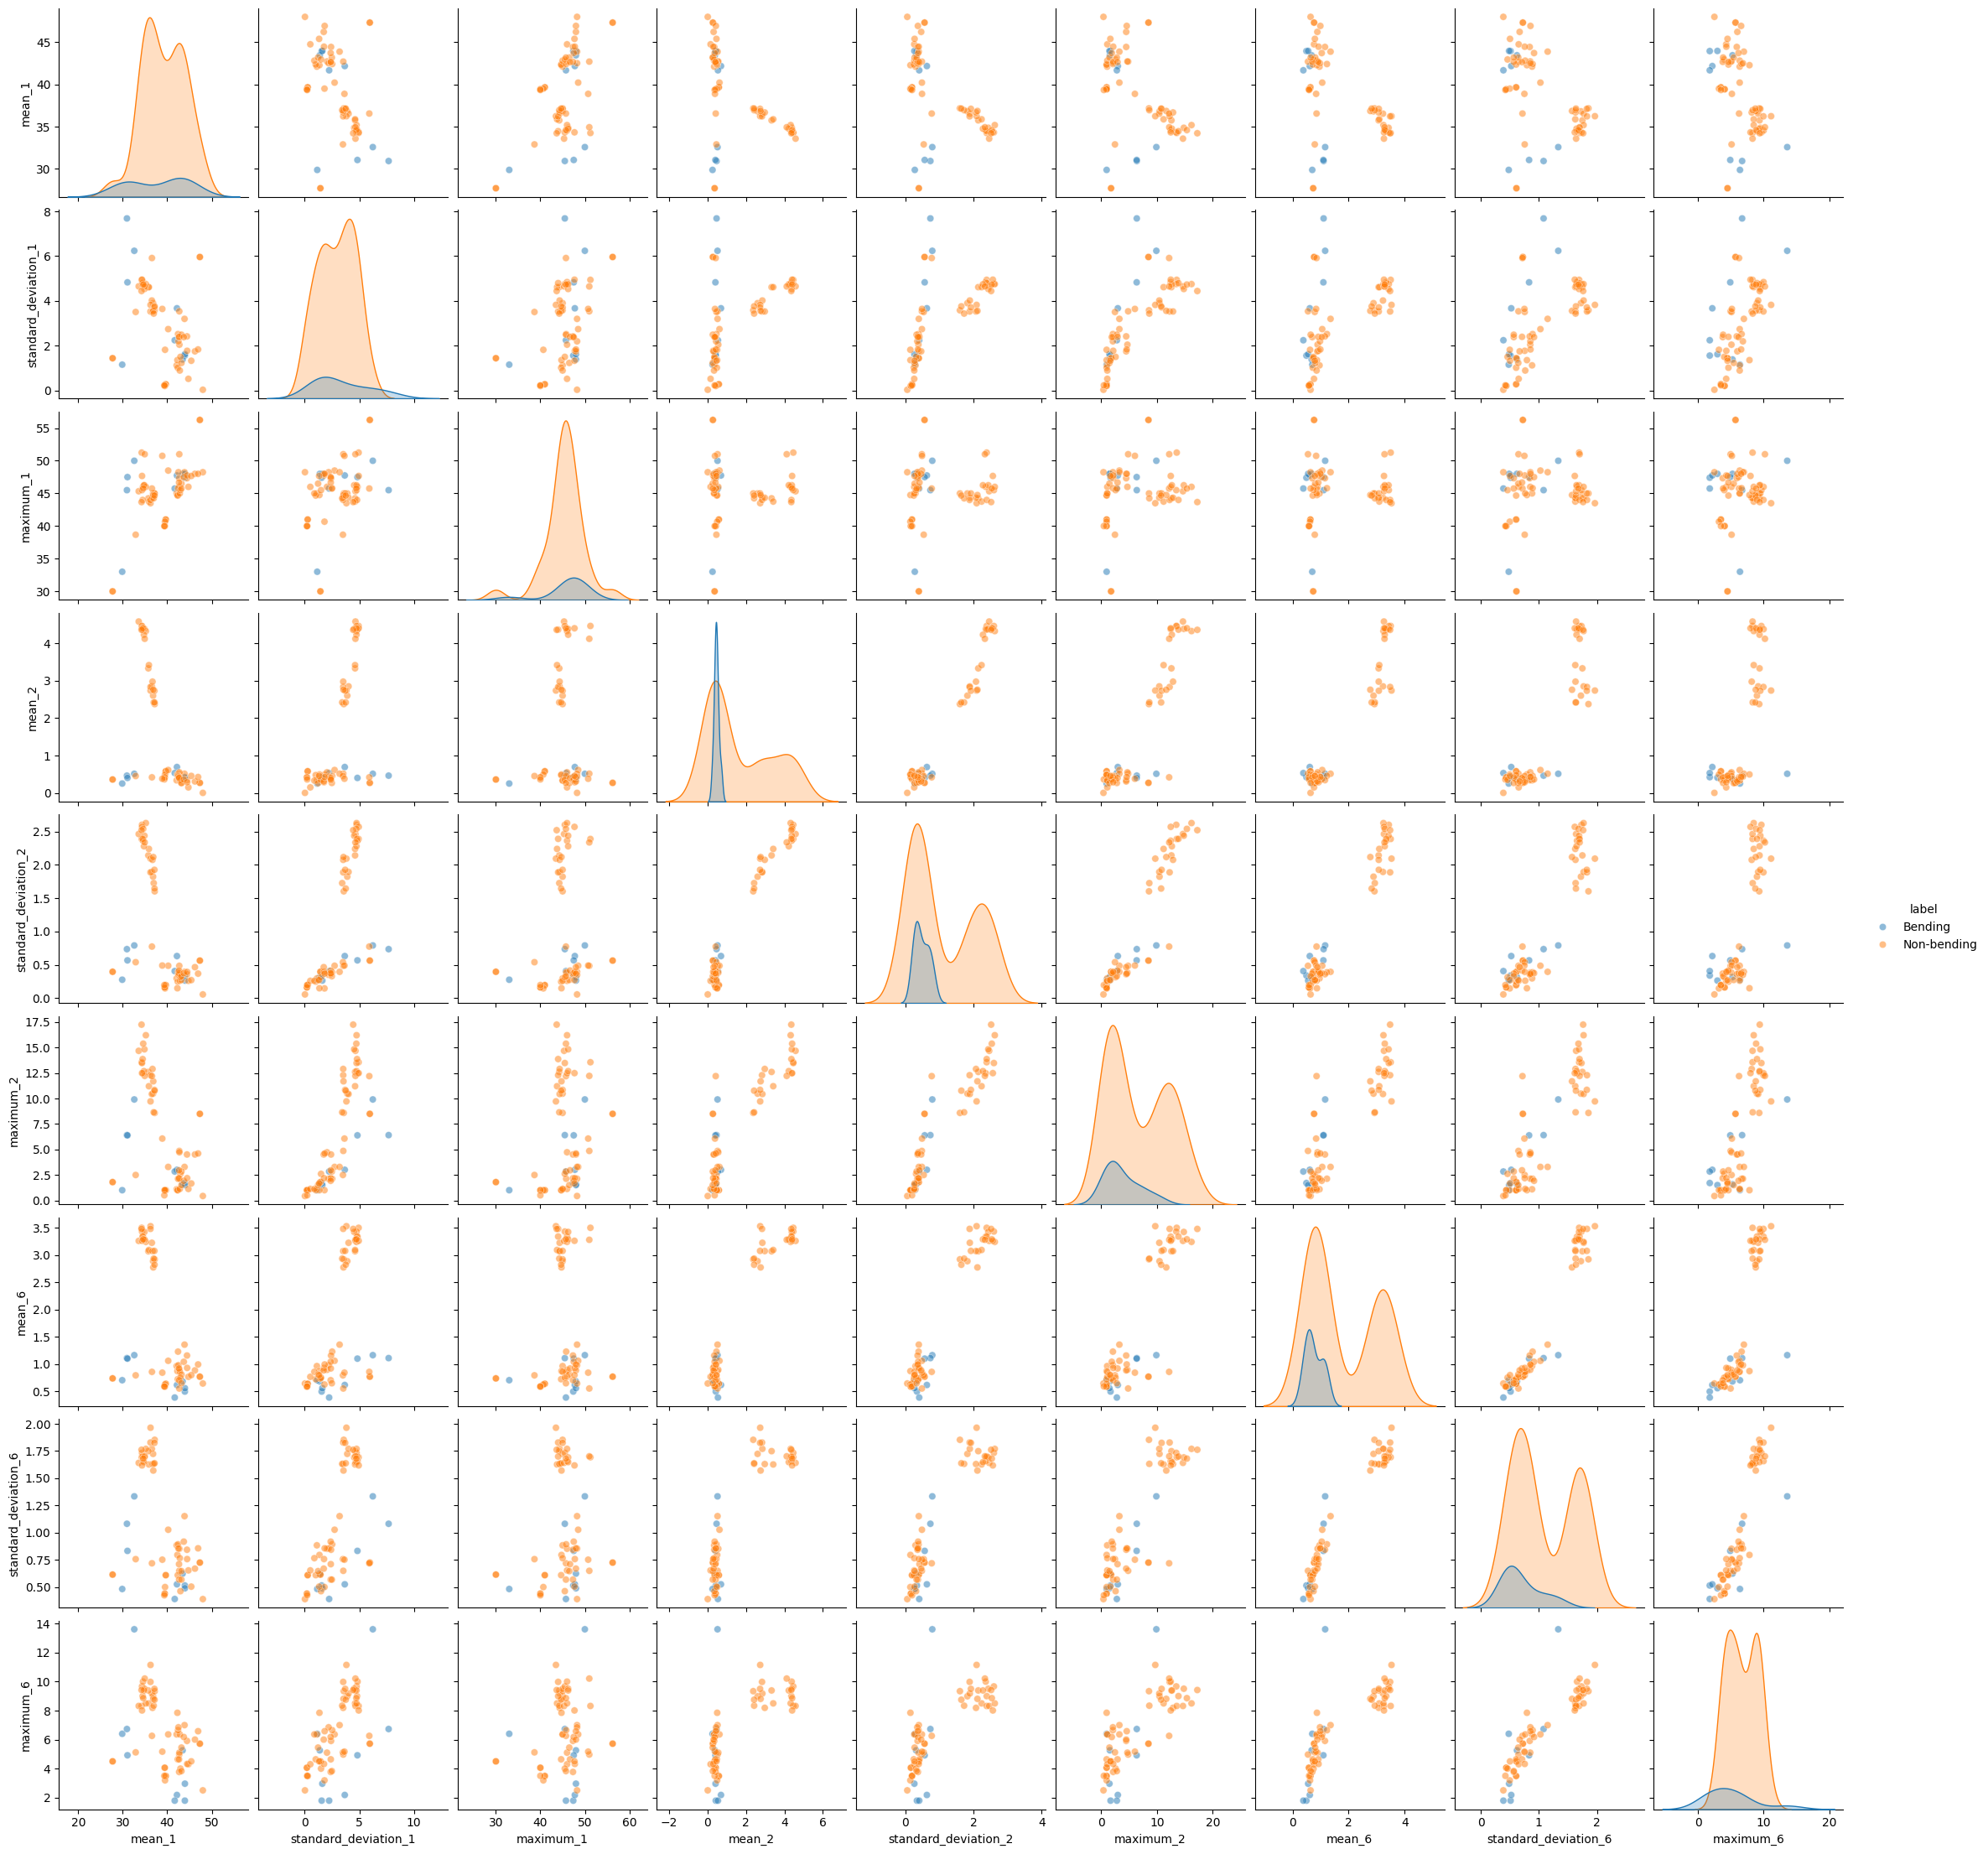

In [13]:
selected_features = ["mean", "standard_deviation", "maximum"]
selected_series = {"1": "avg_rss12", "2": "var_rss12", "6": "var_rss23"}

# Extract features from training data
feature_methods = {
    "mean": "mean",
    "standard_deviation": "std",
    "maximum": "max"
}

rows = []

for (activity, dataset_number), recording in train_data.items():
    row = {
        "label": "Bending" if activity.startswith("bending") else "Non-bending"
    }

    for series_num, col in selected_series.items():
        for feature in selected_features:
            method = feature_methods[feature]
            row[f"{feature}_{series_num}"] = getattr(recording[col], method)()

    rows.append(row)

features_df = pd.DataFrame(rows)

plot_cols = [
    f"{features}_{series_num}"
    for series_num in selected_series
    for features in selected_features
]

sns.pairplot(
    features_df,
    vars=plot_cols,
    hue="label",
    plot_kws={"alpha": 0.5}
)

plt.show()

The scatter plots show that bending and non-bending activities exhibit some separation, particularly for features extracted from time series 2 and 6. However, there is still overlap between the two classes, suggesting that these features may be useful for classification but cannot perfectly distinguish the activities.

#### ii. Splitted Plots

In [14]:
# Split each recording into two halves and extract features
rows_split = []

for (activity, dataset_number), recording in train_data.items():
    row = {
        "label": "Bending" if activity.startswith("bending") else "Non-bending"
    }

    midpoint = len(recording) // 2
    parts = [recording.iloc[:midpoint], recording.iloc[midpoint:]]

    for part_num, part in enumerate(parts, start=1):
        for series_num, col in selected_series.items():
            for feature in selected_features:
                method = feature_methods[feature]
                row[f"{feature}_{series_num}_part{part_num}"] = getattr(part[col], method)()

    rows_split.append(row)

features_split_df = pd.DataFrame(rows_split)

print(features_split_df.shape)

(69, 19)


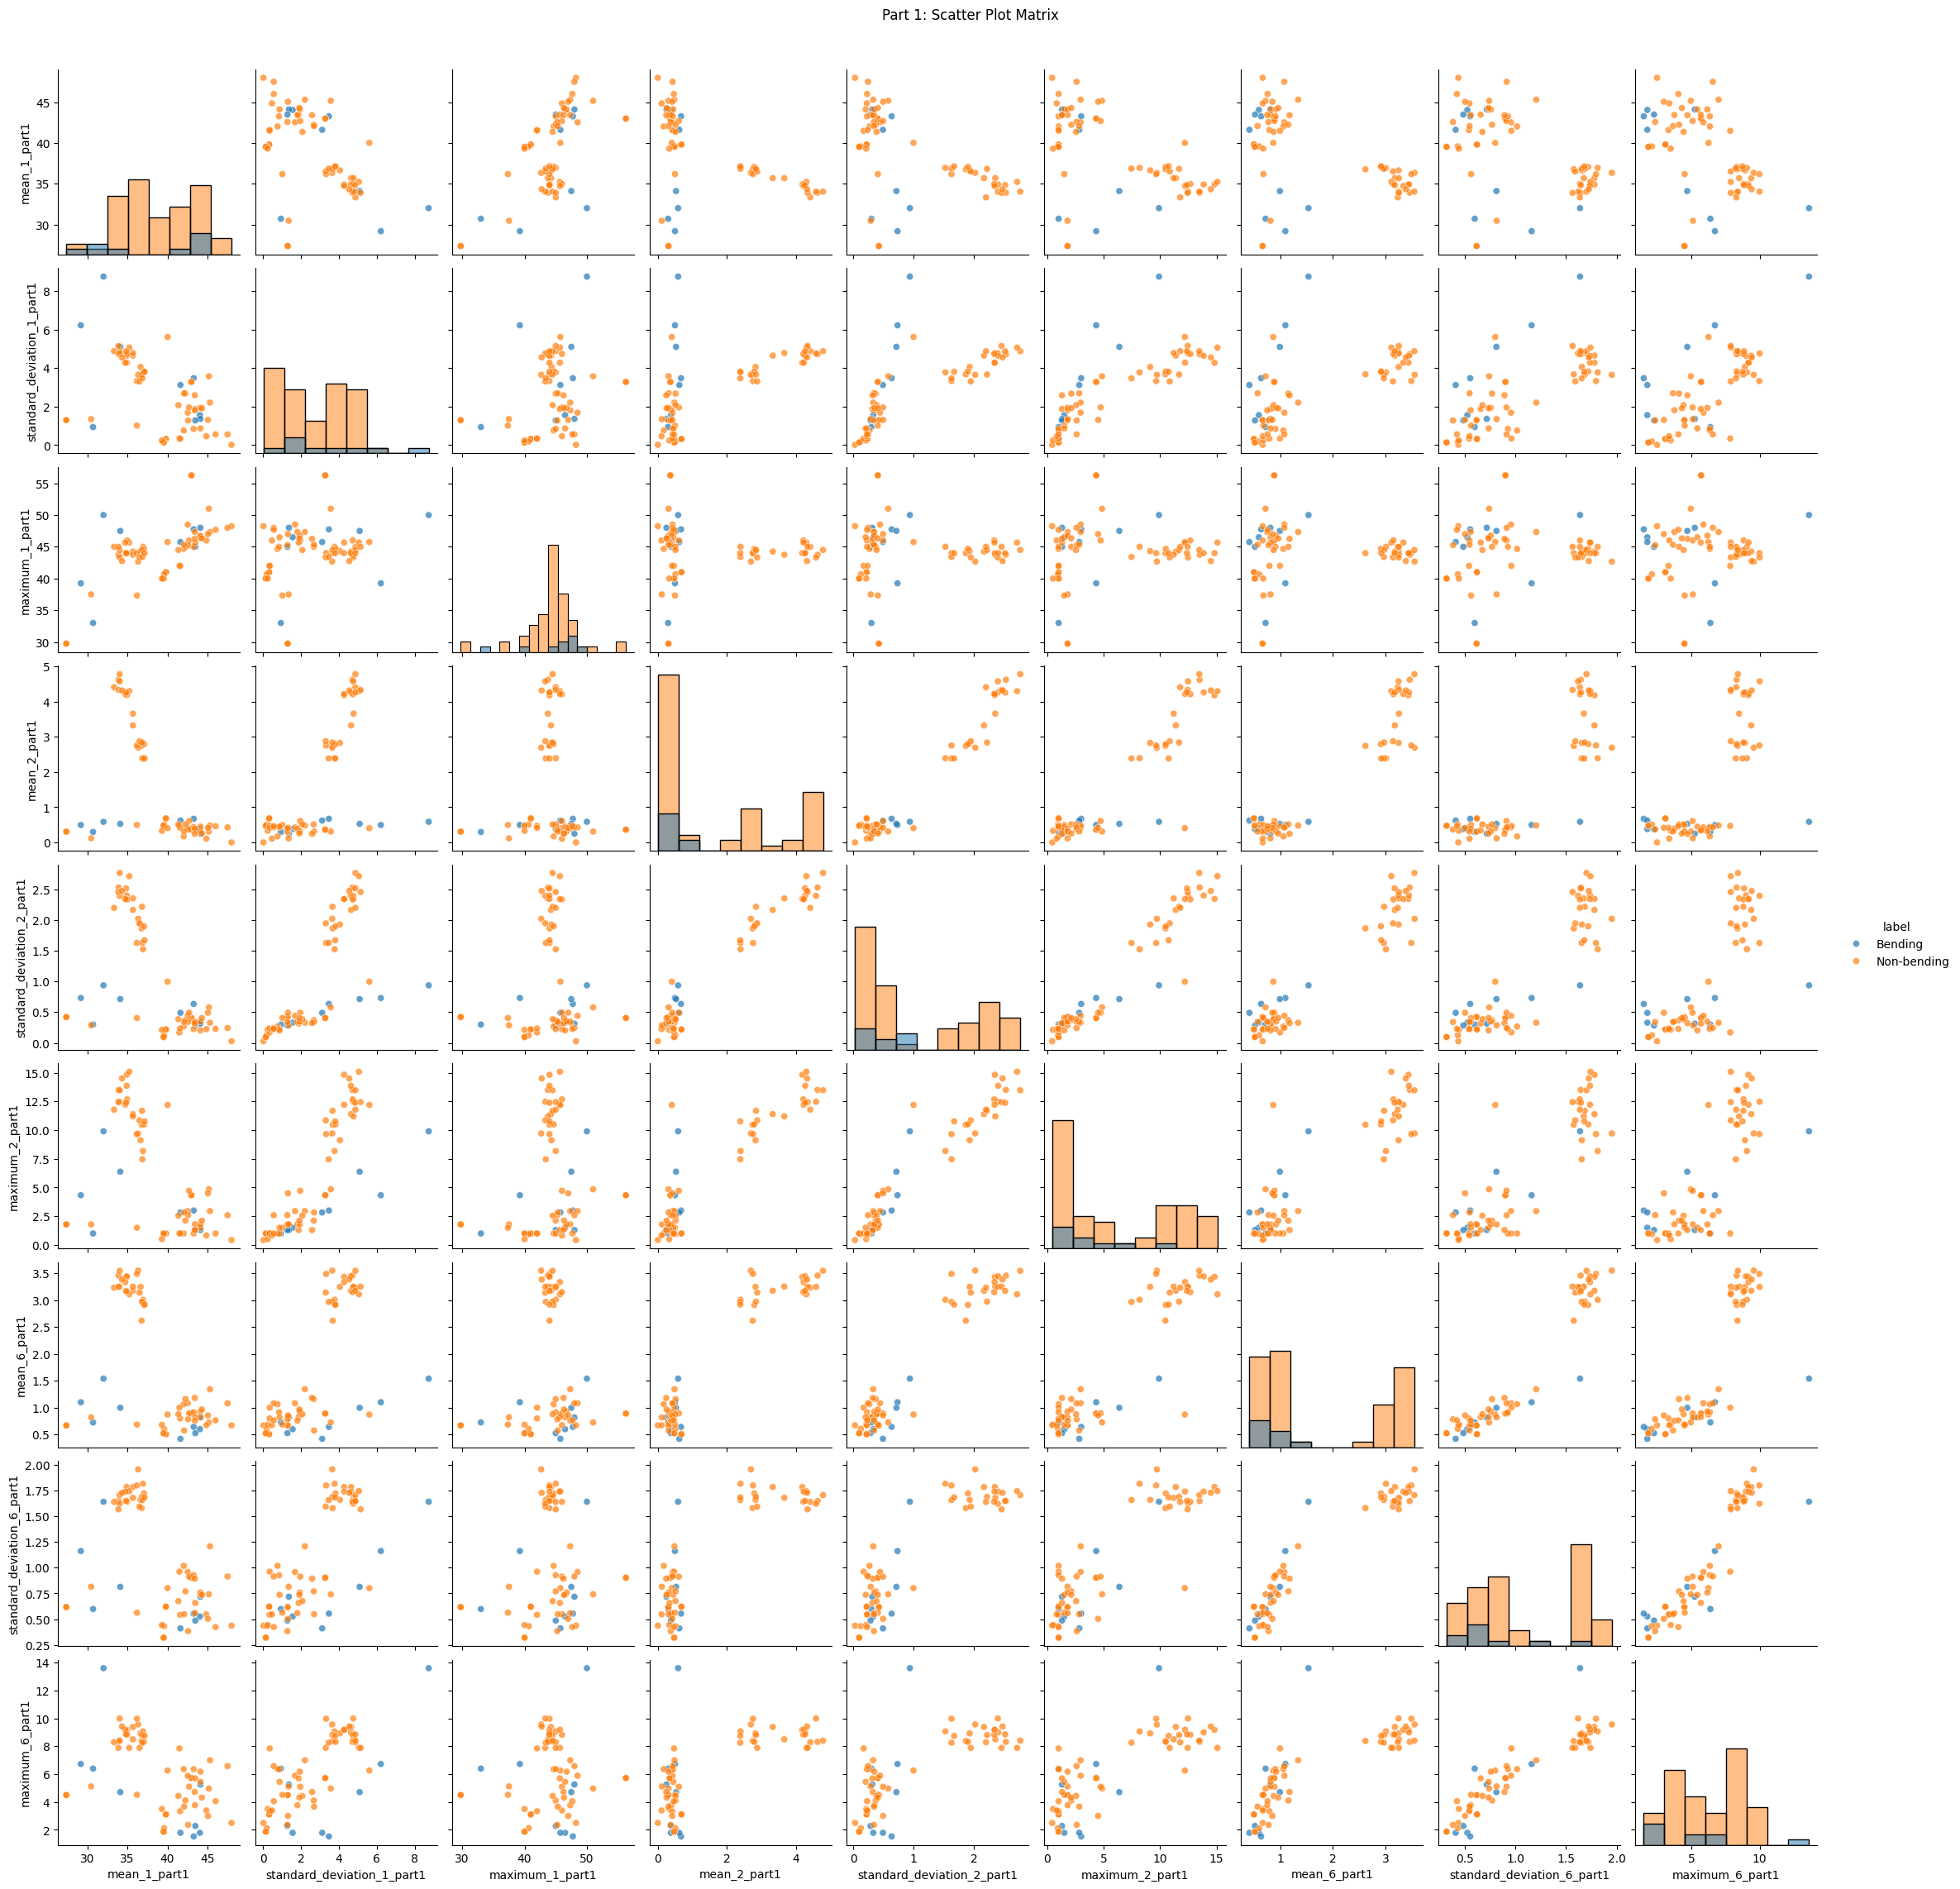

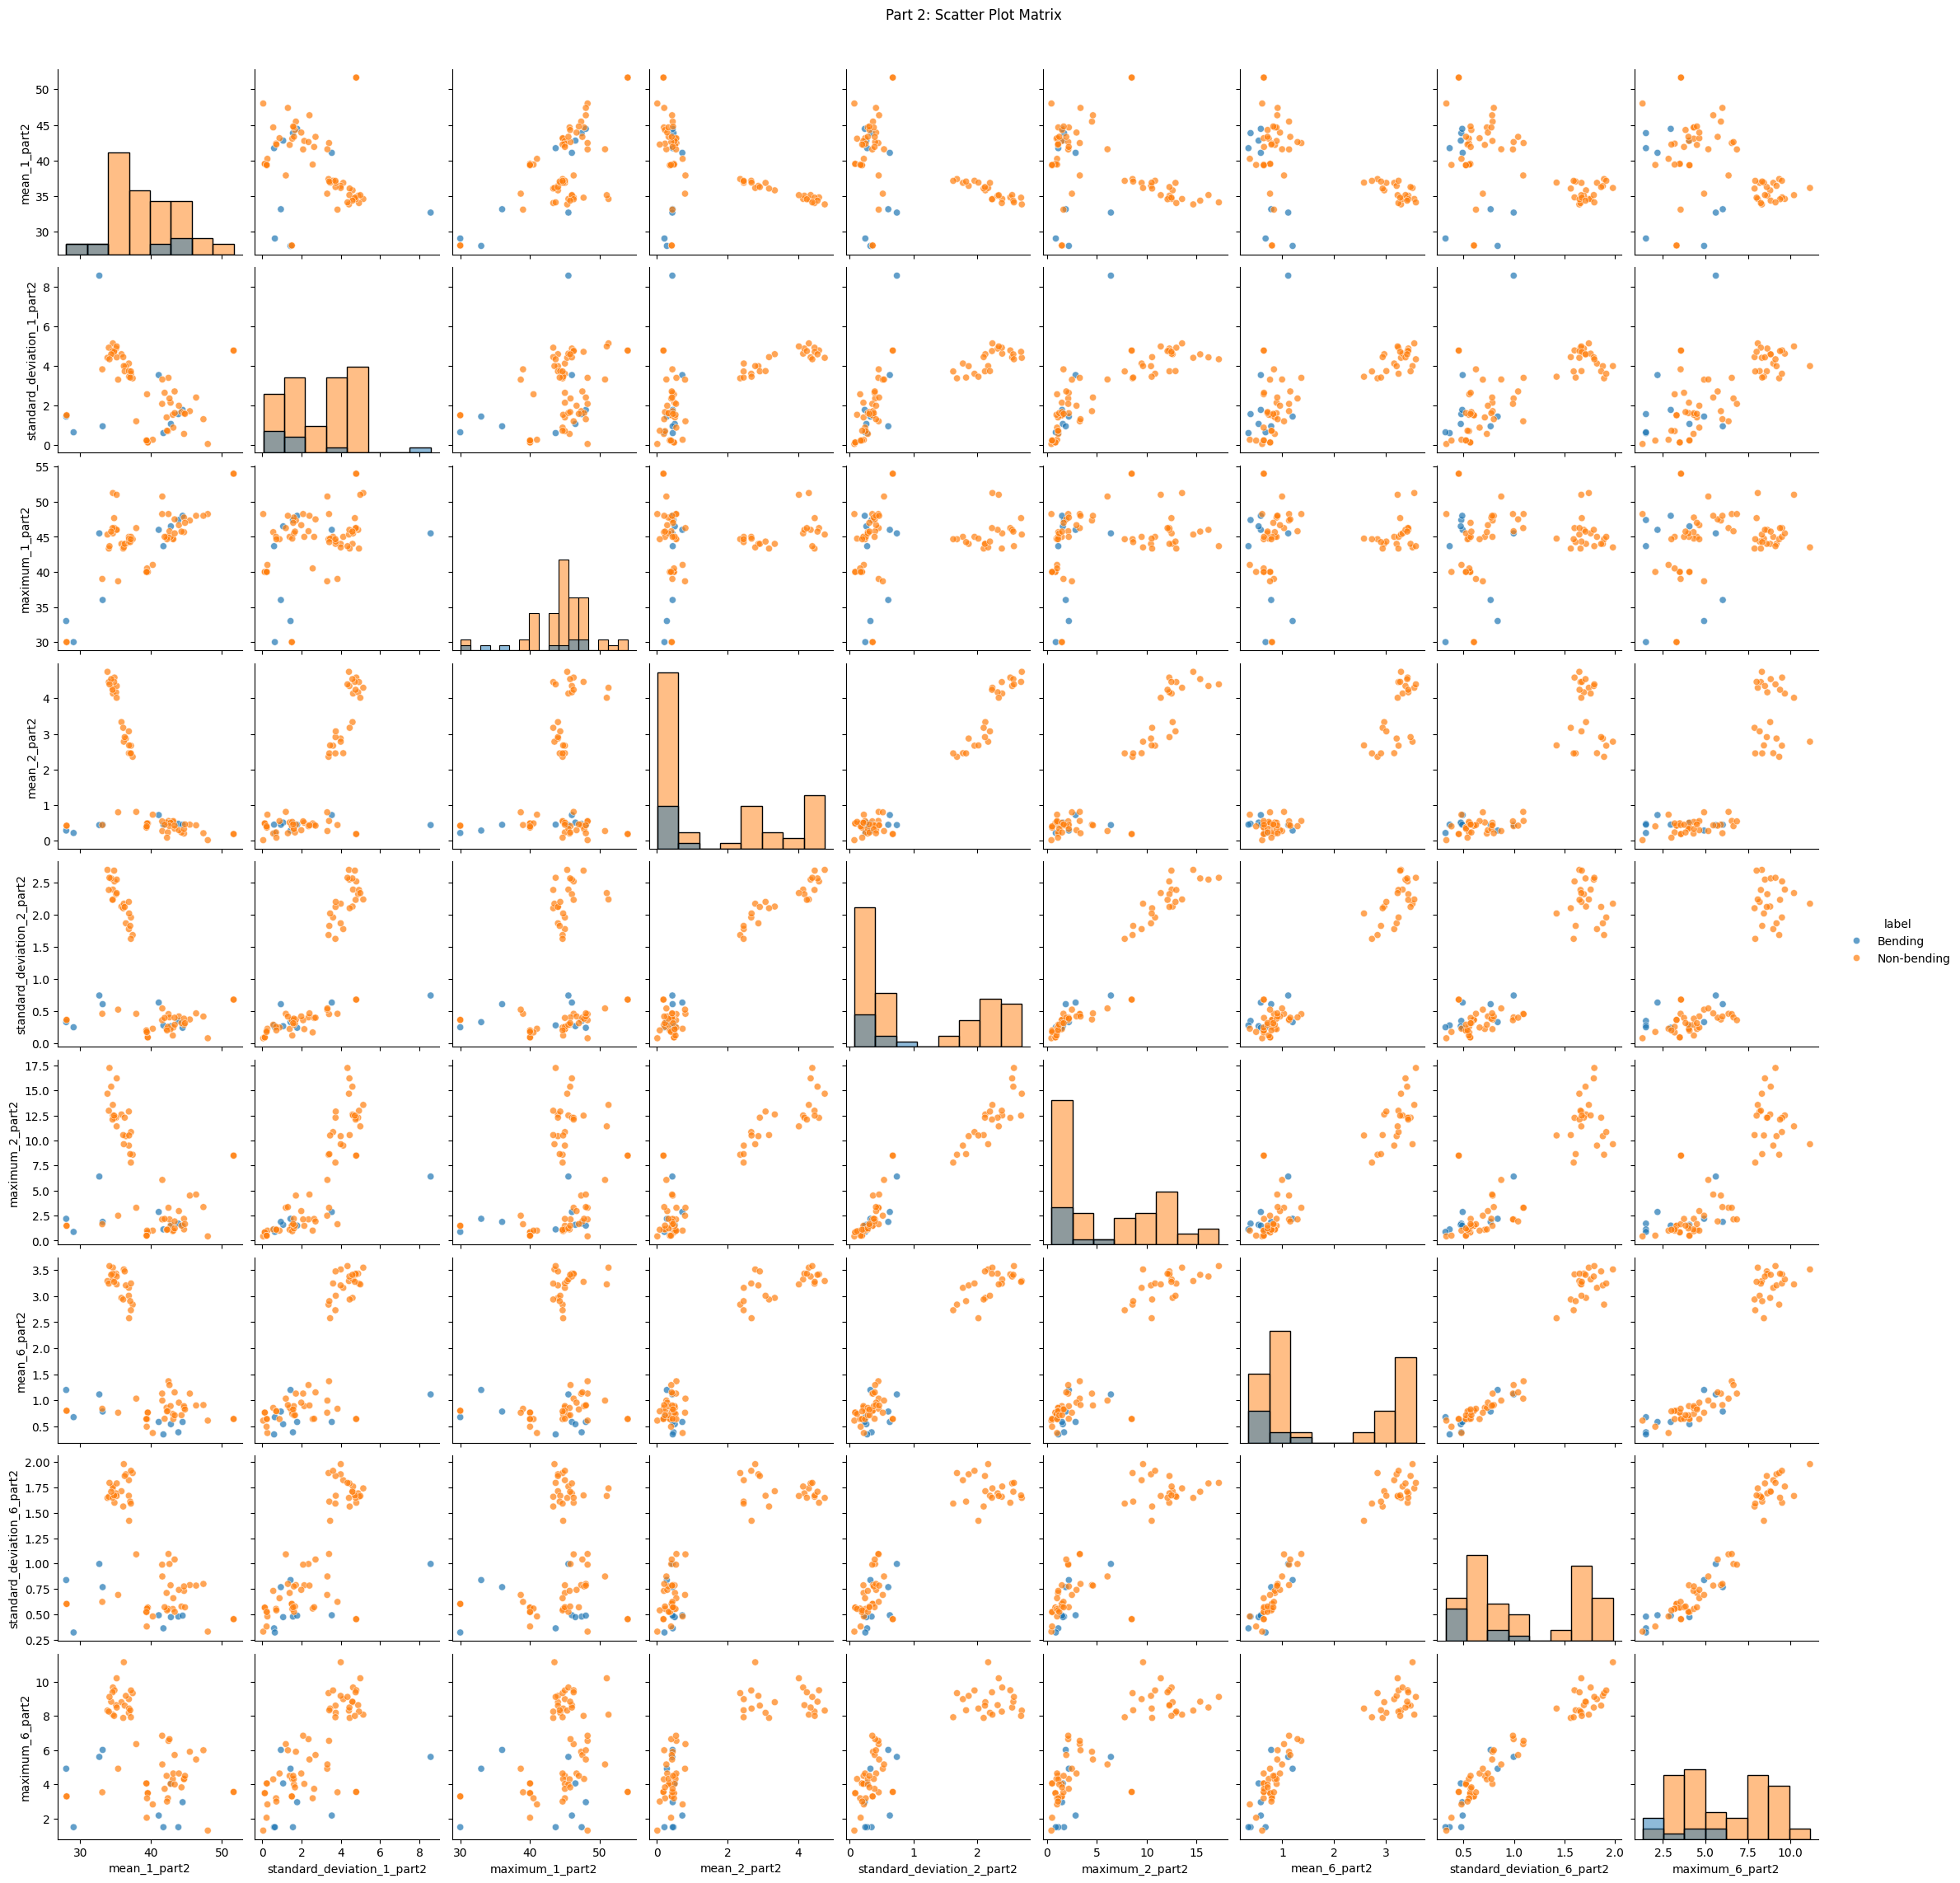

In [15]:
for part_num in [1, 2]:
    plot_cols = [
        f"{feature}_{series_num}_part{part_num}"
        for series_num in selected_series
        for feature in selected_features
    ]

    g = sns.pairplot(
        features_split_df,
        vars=plot_cols,
        hue="label",
        diag_kind="hist",
        plot_kws={"alpha": 0.7, "s": 35}
    )

    g.figure.suptitle(f"Part {part_num}: Scatter Plot Matrix", y=1.02)
    plt.show()

After splitting each time series into two halves, the scatter plots show patterns similar to those in 2(a)i. Features from time series 2 still provide relatively good separation between bending and non-bending activities, while considerable overlap remains in other features. Overall, no substantial improvement in class separability is observed after splitting, although the two halves capture some differences in feature distributions.

#### iii. Time Series Segments

I used the three time-domain features selected in Homework 3, namely mean, standard deviation, and maximum, across all six time series. These features were chosen based on their relevance to activity classification.

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline

# All 6 time series
series_cols = [
    "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13",
    "avg_rss23", "var_rss23"
]

# Selected time-domain features from HW3
feature_methods = {
    "mean": "mean",
    "standard_deviation": "std",
    "maximum": "max"
}

# Extract features for a given l
def extract_features(data, l):
    rows, labels = [], []

    for (activity, dataset_number), recording in data.items():
        row = {}

        parts = np.array_split(
            np.arange(len(recording)), l
        )

        for part_num, indices in enumerate(parts, start=1):
            part = recording.iloc[indices]

            for series_num, col in enumerate(series_cols, start=1):
                for feature, method in feature_methods.items():
                    row[f"{feature}_{series_num}_part{part_num}"] = (
                        getattr(part[col], method)()
                    )

        rows.append(row)
        labels.append(int(activity.startswith("bending")))

    return pd.DataFrame(rows), np.array(labels)


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []
best_score = -1
best_l = None
best_p = None

# Search all l and p combinations
for l in range(1, 21):

    X, y = extract_features(train_data, l)
    n_features = X.shape[1]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("rfe", RFE(
            LogisticRegression(
                max_iter=5000,
                solver="liblinear"
            )
        )),
        ("logistic", LogisticRegression(
            max_iter=5000,
            solver="liblinear"
        ))
    ])

    grid = GridSearchCV(
        pipeline,
        param_grid={
            "rfe__n_features_to_select": list(
                range(1, n_features + 1)
            )
        },
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
        refit=True
    )

    grid.fit(X, y)

    results.append({
        "l": l,
        "p": grid.best_params_["rfe__n_features_to_select"],
        "cv_accuracy": grid.best_score_
    })

    print(
        f"l={l}, "
        f"best p={results[-1]['p']}, "
        f"CV accuracy={grid.best_score_:.4f}"
    )

    if grid.best_score_ > best_score:
        best_score = grid.best_score_
        best_l = l
        best_p = results[-1]["p"]

results_df = pd.DataFrame(results)

print("\nBest l:", best_l)
print("Best p:", best_p)
print(f"Best CV accuracy: {best_score:.4f}")

# Refit final model on the full training set
X_train, y_train = extract_features(train_data, best_l)

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        LogisticRegression(
            max_iter=5000,
            solver="liblinear"
        ),
        n_features_to_select=best_p
    )),
    ("logistic", LogisticRegression(
        max_iter=5000,
        solver="liblinear"
    ))
])

final_model.fit(X_train, y_train)

selected_features_final = X_train.columns[
    final_model.named_steps["rfe"].support_
]

print("\nSelected features:")
print(selected_features_final.tolist())

display(results_df)

l=1, best p=4, CV accuracy=0.9857
l=2, best p=1, CV accuracy=0.9571
l=3, best p=1, CV accuracy=0.9714
l=4, best p=2, CV accuracy=0.9714
l=5, best p=1, CV accuracy=0.9714
l=6, best p=1, CV accuracy=0.9714
l=7, best p=1, CV accuracy=0.9714
l=8, best p=2, CV accuracy=0.9571
l=9, best p=2, CV accuracy=0.9571
l=10, best p=15, CV accuracy=0.9857
l=11, best p=1, CV accuracy=0.9714
l=12, best p=17, CV accuracy=0.9714
l=13, best p=11, CV accuracy=0.9714
l=14, best p=1, CV accuracy=0.9571
l=15, best p=28, CV accuracy=0.9714
l=16, best p=11, CV accuracy=0.9571
l=17, best p=13, CV accuracy=0.9571
l=18, best p=2, CV accuracy=0.9714
l=19, best p=1, CV accuracy=0.9714
l=20, best p=1, CV accuracy=0.9714

Best l: 1
Best p: 4
Best CV accuracy: 0.9857

Selected features:
['mean_1_part1', 'mean_5_part1', 'maximum_5_part1', 'standard_deviation_6_part1']


,l,p,cv_accuracy
0,1,4,0.985714
1,2,1,0.957143
2,3,1,0.971429
3,4,2,0.971429
4,5,1,0.971429
5,6,1,0.971429
6,7,1,0.971429
7,8,2,0.957143
8,9,2,0.957143
9,10,15,0.985714


Using RFE with stratified 5-fold cross-validation, the optimal configuration was \(l=1\) and \(p=4\), achieving a mean CV accuracy of **98.57%**.

The four selected features were mean_1, mean_5, maximum_5, and standard_deviation_6. Although \(l=10\) and \(p=15\) achieved the same accuracy, the simpler configuration was preferred because it required fewer features.

This suggests that splitting the time series is not necessary to achieve strong classification performance on this dataset.

#### iv. Confusion Matrix

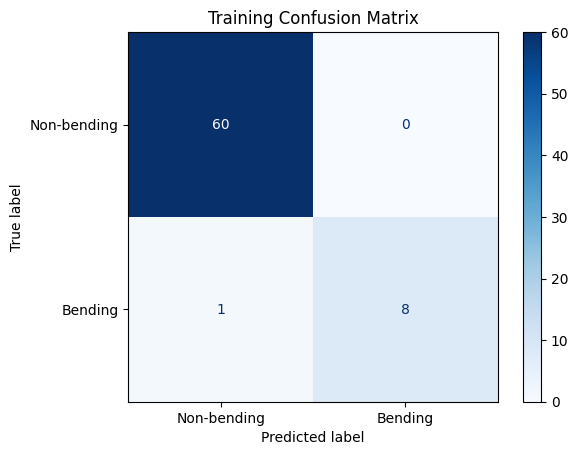

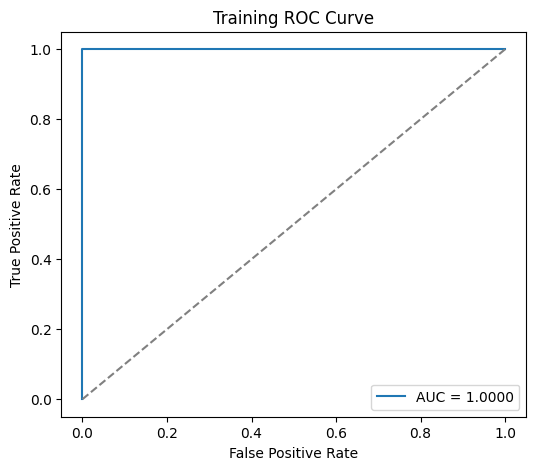

Training accuracy: 0.9855
Training AUC: 1.0000

Final model coefficients:


,Feature,Coefficient
0,mean_1_part1,-0.615079
1,mean_5_part1,0.956847
2,maximum_5_part1,1.268617
3,standard_deviation_6_part1,-0.872388


Statsmodels estimation failed: Singular matrix
This may indicate separation or numerical instability.


/Users/xiada/keck_venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:2385: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))
/Users/xiada/keck_venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:2443: RuntimeWarning: divide by zero encountered in log
  return np.sum(np.log(self.cdf(q * linpred)))


In [20]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, accuracy_score
)
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Training predictions
X_train, y_train = extract_features(train_data, best_l)

y_train_pred = final_model.predict(X_train)
y_train_prob = final_model.predict_proba(X_train)[:, 1]

# Confusion Matrix
cm_train = confusion_matrix(y_train, y_train_pred)

ConfusionMatrixDisplay(
    cm_train,
    display_labels=["Non-bending", "Bending"]
).plot(cmap="Blues")

plt.title("Training Confusion Matrix")
plt.show()

# ROC and AUC
fpr, tpr, _ = roc_curve(y_train, y_train_prob)
auc_train = roc_auc_score(y_train, y_train_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_train:.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend()
plt.show()

print(f"Training accuracy: {accuracy_score(y_train, y_train_pred):.4f}")
print(f"Training AUC: {auc_train:.4f}")

# Logistic regression coefficients from final sklearn model
coef_df = pd.DataFrame({
    "Feature": selected_features_final,
    "Coefficient": final_model.named_steps["logistic"].coef_[0]
})

print("\nFinal model coefficients:")
display(coef_df)

# Statistical inference using statsmodels
X_scaled = final_model.named_steps["scaler"].transform(X_train)
X_selected = final_model.named_steps["rfe"].transform(X_scaled)
X_sm = sm.add_constant(X_selected, has_constant="add")

try:
    logit_sm = sm.Logit(y_train, X_sm).fit(disp=False)

    inference_df = pd.DataFrame({
        "Feature": ["Intercept"] + list(selected_features_final),
        "Coefficient": logit_sm.params,
        "P-value": logit_sm.pvalues
    })

    print("\nUnpenalized Logistic Regression Inference:")
    display(inference_df)

except Exception as e:
    print("Statsmodels estimation failed:", e)
    print("This may indicate separation or numerical instability.")

**2(a)iv — Training Performance**

The Logistic Regression model achieved a training accuracy of **98.55%** and an AUC of **1.0000**. The confusion matrix shows 60 true negatives, 8 true positives, 0 false positives, and 1 false negative.

The four selected features have coefficients of -0.6151, 0.9568, 1.2686, and -0.8724, respectively.

The unpenalized Logistic Regression model failed to estimate reliable p-values due to a singular matrix, suggesting possible complete separation and numerical instability. Therefore, valid p-values could not be reported using standard maximum likelihood estimation.

#### v. Test Classifier

CV Accuracy: 0.9857
Test Accuracy: 1.0000
Test AUC: 1.0000


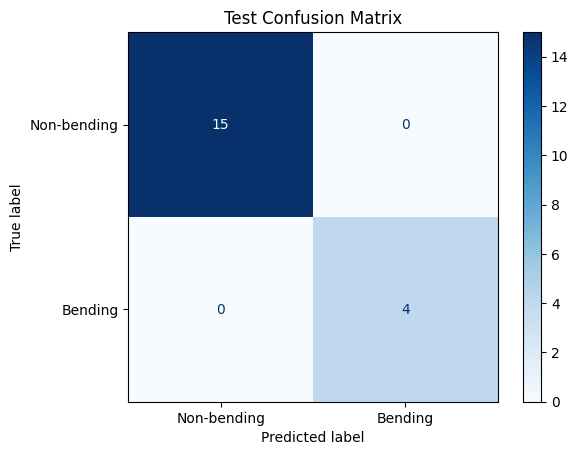

In [22]:
# Extract test features using the same best_l
X_test, y_test = extract_features(test_data, best_l)

# Ensure identical feature order
X_test = X_test[X_train.columns]

# Predict without refitting
y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

test_accuracy = accuracy_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_prob)

print(f"CV Accuracy: {best_score:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test AUC: {test_auc:.4f}")

# Test Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Non-bending", "Bending"],
    cmap="Blues"
)
plt.title("Test Confusion Matrix")
plt.show()

The test time series were processed using the same optimal segmentation (\(l=1\)) and selected features as the training set.

The classifier achieved a **test accuracy of 100%**, compared with a **5-fold cross-validation accuracy of 98.57%**. All 19 test instances were correctly classified (15 non-bending and 4 bending), indicating strong generalization performance on the test set.

#### vi. Separation

Yes. The classes appear to be perfectly linearly separable, as indicated by the training AUC of 1.0 and perfect probability ranking. Under complete separation, maximum likelihood estimation can continuously increase the magnitude of logistic regression coefficients to push predicted probabilities closer to 0 or 1, without reaching a finite optimum. This causes numerical instability, consistent with the singular matrix error encountered during estimation.

#### vii. Imbalance

Original class distribution:
0    60
1     9
Name: count, dtype: int64


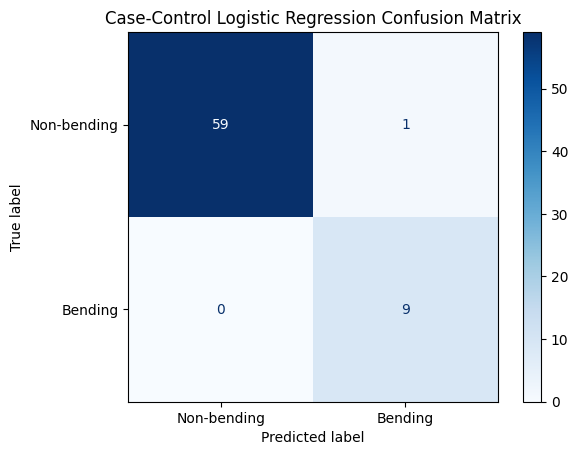

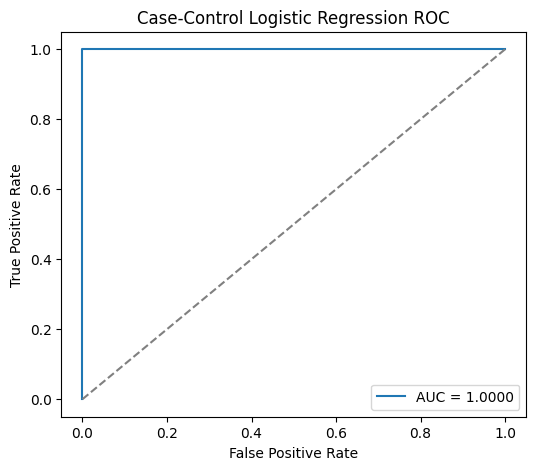

Case-Control Accuracy: 0.9855
Case-Control AUC: 1.0000
Adjusted intercept: -11.7067


In [23]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

# Check original class distribution
print("Original class distribution:")
print(pd.Series(y_train).value_counts())

# Case-control sampling
rng = np.random.default_rng(42)

idx_bending = np.where(y_train == 1)[0]
idx_nonbending = np.where(y_train == 0)[0]

idx_nonbending_sampled = rng.choice(
    idx_nonbending,
    size=len(idx_bending),
    replace=False
)

sample_idx = np.concatenate([
    idx_bending,
    idx_nonbending_sampled
])

# Use features selected in iii, with the same fitted scaling
X_scaled = final_model.named_steps["scaler"].transform(X_train)
X_selected = final_model.named_steps["rfe"].transform(X_scaled)

X_balanced = X_selected[sample_idx]
y_balanced = y_train[sample_idx]

# Fit case-control logistic regression
cc_model = LogisticRegression(
    max_iter=5000,
    solver="liblinear",
    C=1e6
)

cc_model.fit(X_balanced, y_balanced)

# Adjust intercept for original class proportions
original_prior = y_train.mean()
sample_prior = y_balanced.mean()

intercept_adjustment = (
    np.log(original_prior / (1 - original_prior))
    - np.log(sample_prior / (1 - sample_prior))
)

adjusted_intercept = (
    cc_model.intercept_[0] + intercept_adjustment
)

# Predict on original training data
log_odds = (
    X_selected @ cc_model.coef_[0]
    + adjusted_intercept
)

prob_adjusted = 1 / (1 + np.exp(-log_odds))
pred_adjusted = (prob_adjusted >= 0.5).astype(int)

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_train,
    pred_adjusted,
    display_labels=["Non-bending", "Bending"],
    cmap="Blues"
)

plt.title("Case-Control Logistic Regression Confusion Matrix")
plt.show()

# ROC and AUC
fpr_cc, tpr_cc, _ = roc_curve(y_train, prob_adjusted)
auc_cc = roc_auc_score(y_train, prob_adjusted)

plt.figure(figsize=(6, 5))
plt.plot(fpr_cc, tpr_cc, label=f"AUC = {auc_cc:.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control Logistic Regression ROC")
plt.legend()
plt.show()

print(f"Case-Control Accuracy: {accuracy_score(y_train, pred_adjusted):.4f}")
print(f"Case-Control AUC: {auc_cc:.4f}")
print(f"Adjusted intercept: {adjusted_intercept:.4f}")

The training set is imbalanced, with 9 bending and 60 non-bending instances. We applied case-control sampling by undersampling the majority class and adjusted the logistic regression intercept to account for the original class proportions.

The adjusted model achieved a training accuracy of **98.55%** and an **AUC of 1.0000**. The confusion matrix shows 59 true negatives, 9 true positives, 1 false positive, and 0 false negatives.

Compared with the original model, case-control sampling improved bending recall from 88.89% to 100%, while maintaining the same overall accuracy and AUC.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [24]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV

# Stratified 5-fold CV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Candidate C values
C_values = np.logspace(-3, 3, 15)

results_l1 = []
best_score_l1 = -1
best_l_l1 = None
best_C_l1 = None

# Cross-validation for both l and C
for l in range(1, 21):

    X, y = extract_features(train_data, l)

    pipeline_l1 = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            max_iter=5000
        ))
    ])

    grid_l1 = GridSearchCV(
        pipeline_l1,
        param_grid={"logistic__C": C_values},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
        refit=True
    )

    grid_l1.fit(X, y)

    results_l1.append({
        "l": l,
        "C": grid_l1.best_params_["logistic__C"],
        "cv_accuracy": grid_l1.best_score_
    })

    print(
        f"l={l}, "
        f"best C={grid_l1.best_params_['logistic__C']:.4f}, "
        f"CV accuracy={grid_l1.best_score_:.4f}"
    )

    if grid_l1.best_score_ > best_score_l1:
        best_score_l1 = grid_l1.best_score_
        best_l_l1 = l
        best_C_l1 = grid_l1.best_params_["logistic__C"]

# Results summary
results_l1_df = pd.DataFrame(results_l1)

print("\nBest l:", best_l_l1)
print("Best C:", best_C_l1)
print(f"Best CV accuracy: {best_score_l1:.4f}")

# Fit final L1 model
X_train_l1, y_train_l1 = extract_features(
    train_data, best_l_l1
)

final_l1_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l1",
        C=best_C_l1,
        solver="liblinear",
        max_iter=5000
    ))
])

final_l1_model.fit(X_train_l1, y_train_l1)

# Selected features: non-zero coefficients
coefficients_l1 = final_l1_model.named_steps["logistic"].coef_[0]

selected_features_l1 = X_train_l1.columns[
    np.abs(coefficients_l1) > 1e-6
]

print("\nNumber of selected features:", len(selected_features_l1))
print("Selected features:")
print(selected_features_l1.tolist())

display(results_l1_df)

/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead 

l=1, best C=2.6827, CV accuracy=0.9714


/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead 

l=2, best C=2.6827, CV accuracy=0.9429


/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead 

...

l=19, best C=1.0000, CV accuracy=0.9714


/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead 

l=20, best C=7.1969, CV accuracy=0.9714

Best l: 1
Best C: 2.6826957952797246
Best CV accuracy: 0.9714

Number of selected features: 7
Selected features:
['mean_1_part1', 'maximum_2_part1', 'mean_3_part1', 'mean_5_part1', 'standard_deviation_5_part1', 'maximum_5_part1', 'standard_deviation_6_part1']


/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead 

,l,C,cv_accuracy
0,1,2.682696,0.971429
1,2,2.682696,0.942857
2,3,0.372759,0.971429
3,4,0.372759,0.957143
4,5,1.000000,0.927473
5,6,0.372759,0.942857
6,7,0.372759,0.927473
7,8,372.759372,0.957143
8,9,1000.000000,0.928571
9,10,372.759372,0.971429


Using L1-penalized Logistic Regression with stratified 5-fold cross-validation, the optimal configuration was \(l=1\) and \(C=2.6827\), achieving a mean CV accuracy of **97.14%**.

The L1 penalty automatically selected 7 out of 18 features by shrinking the remaining coefficients to zero. The results suggest that further splitting the time series is unnecessary for achieving strong classification performance.

#### ii. Comparison

In [25]:
comparison_df = pd.DataFrame({
    "Method": ["RFE + Logistic Regression", "L1 Logistic Regression"],
    "Best l": [best_l, best_l_l1],
    "Selected Features": [best_p, len(selected_features_l1)],
    "CV Accuracy": [best_score, best_score_l1]
})

display(comparison_df)

if best_score_l1 > best_score:
    print("L1 Logistic Regression performs better.")
elif best_score_l1 < best_score:
    print("RFE Logistic Regression performs better.")
else:
    print("Both methods achieve the same CV accuracy.")

,Method,Best l,Selected Features,CV Accuracy
0,RFE + Logistic Regression,1,4,0.985714
1,L1 Logistic Regression,1,7,0.971429


RFE Logistic Regression performs better.


RFE with Logistic Regression achieved a higher CV accuracy (**98.57%**) than L1-penalized Logistic Regression (**97.14%**), while selecting fewer features (4 vs. 7). Therefore, RFE performed slightly better in this experiment.

However, L1-penalized Logistic Regression is easier to implement because it performs feature selection and model fitting simultaneously, whereas RFE requires iterative feature elimination.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve,
    auc, roc_auc_score
)
from sklearn.preprocessing import label_binarize

# Extract multiclass features
def extract_multiclass_features(data, l):
    rows, labels = [], []

    for (activity, dataset_number), recording in data.items():
        row = {}

        parts = np.array_split(np.arange(len(recording)), l)

        for part_num, indices in enumerate(parts, start=1):
            part = recording.iloc[indices]

            for series_num, col in enumerate(series_cols, start=1):
                for feature, method in feature_methods.items():
                    row[f"{feature}_{series_num}_part{part_num}"] = (
                        getattr(part[col], method)()
                    )

        rows.append(row)
        labels.append(activity)

    return pd.DataFrame(rows), np.array(labels)


cv_multi = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

C_values = np.logspace(-3, 3, 15)

results_multi = []
best_score_multi = -1
best_l_multi = None
best_C_multi = None

for l in range(1, 21):
    X, y = extract_multiclass_features(train_data, l)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            penalty="l1",
            solver="saga",
            max_iter=10000,
            random_state=42
        ))
    ])

    grid = GridSearchCV(
        pipeline,
        {"logistic__C": C_values},
        cv=cv_multi,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X, y)

    results_multi.append({
        "l": l,
        "C": grid.best_params_["logistic__C"],
        "cv_accuracy": grid.best_score_
    })

    if grid.best_score_ > best_score_multi:
        best_score_multi = grid.best_score_
        best_l_multi = l
        best_C_multi = grid.best_params_["logistic__C"]

    print(f"l={l}, CV accuracy={grid.best_score_:.4f}")

print("\nBest l:", best_l_multi)
print("Best C:", best_C_multi)
print(f"Best CV accuracy: {best_score_multi:.4f}")

/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in

l=1, CV accuracy=0.8989


/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead 

l=2, CV accuracy=0.9286


/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in

...

l=18, CV accuracy=0.8703


/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in

l=19, CV accuracy=0.8549


/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in

l=20, CV accuracy=0.7978

Best l: 2
Best C: 138.9495494373136
Best CV accuracy: 0.9286


/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Test accuracy: 0.7895
Test error: 0.2105


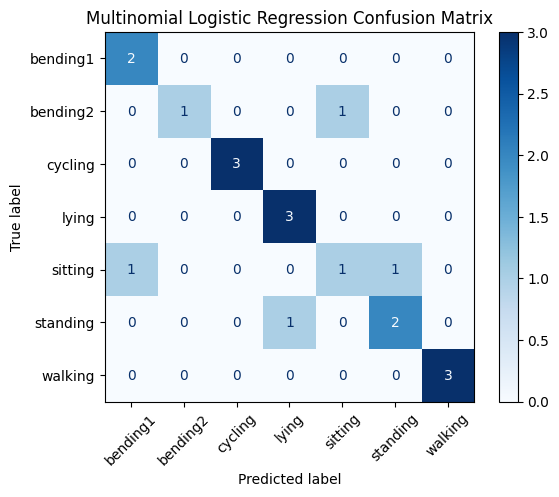

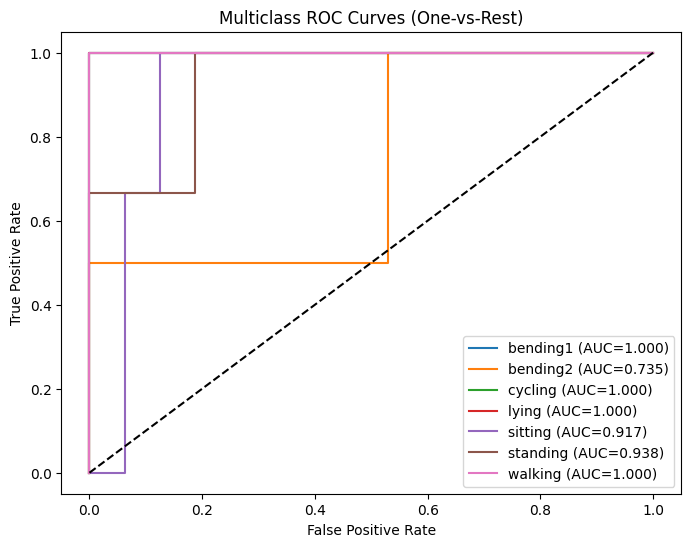

In [27]:
X_train_multi, y_train_multi = extract_multiclass_features(
    train_data, best_l_multi
)
X_test_multi, y_test_multi = extract_multiclass_features(
    test_data, best_l_multi
)

X_test_multi = X_test_multi[X_train_multi.columns]

final_multi_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l1",
        C=best_C_multi,
        solver="saga",
        max_iter=10000,
        random_state=42
    ))
])

final_multi_model.fit(X_train_multi, y_train_multi)

y_pred_multi = final_multi_model.predict(X_test_multi)
y_prob_multi = final_multi_model.predict_proba(X_test_multi)

test_accuracy_multi = accuracy_score(y_test_multi, y_pred_multi)
test_error_multi = 1 - test_accuracy_multi

print(f"Test accuracy: {test_accuracy_multi:.4f}")
print(f"Test error: {test_error_multi:.4f}")

# Multiclass confusion matrix
classes = final_multi_model.named_steps["logistic"].classes_

ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    y_pred_multi,
    labels=classes,
    display_labels=classes,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Multinomial Logistic Regression Confusion Matrix")
plt.show()

# One-vs-Rest ROC curves
y_test_bin = label_binarize(y_test_multi, classes=classes)

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(classes):
    if len(np.unique(y_test_bin[:, i])) < 2:
        continue

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_prob_multi[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"{class_name} (AUC={class_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves (One-vs-Rest)")
plt.legend()
plt.show()

Using L1-penalized multinomial logistic regression with 5-fold cross-validation, the optimal parameters were **l = 2** and **C = 138.95**, achieving a CV accuracy of **92.86%**.

The test error was **21.05%** (4 out of 19 instances misclassified). The confusion matrix shows that most misclassifications occurred among bending2, sitting, and standing. The One-vs-Rest ROC curves show perfect AUCs (1.0) for bending1, cycling, lying, and walking, while bending2 had the lowest AUC (0.735).

#### ii. Naive Bayes

In [28]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score

nb_results = []

nb_models = {
    "GaussianNB": Pipeline([
        ("scaler", StandardScaler()),
        ("nb", GaussianNB())
    ]),
    "MultinomialNB": Pipeline([
        ("scaler", MinMaxScaler()),
        ("nb", MultinomialNB())
    ])
}

for model_name, pipeline in nb_models.items():

    for l in range(1, 21):
        X, y = extract_multiclass_features(train_data, l)

        scores = cross_val_score(
            pipeline,
            X,
            y,
            cv=cv_multi,
            scoring="accuracy",
            n_jobs=-1
        )

        nb_results.append({
            "Model": model_name,
            "l": l,
            "CV Accuracy": scores.mean()
        })

nb_results_df = pd.DataFrame(nb_results)

best_nb_results = (
    nb_results_df
    .sort_values(["CV Accuracy", "l"], ascending=[False, True])
    .drop_duplicates("Model")
)

display(best_nb_results)

/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Users/xiada/keck_venv/lib/python3.11/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  

,Model,l,CV Accuracy
0,GaussianNB,1,0.884615
24,MultinomialNB,5,0.783516


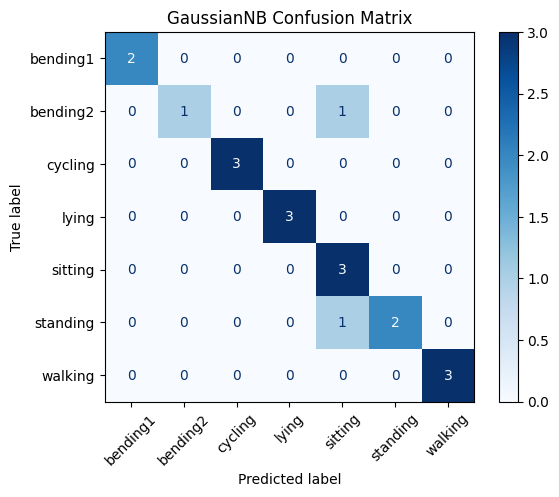

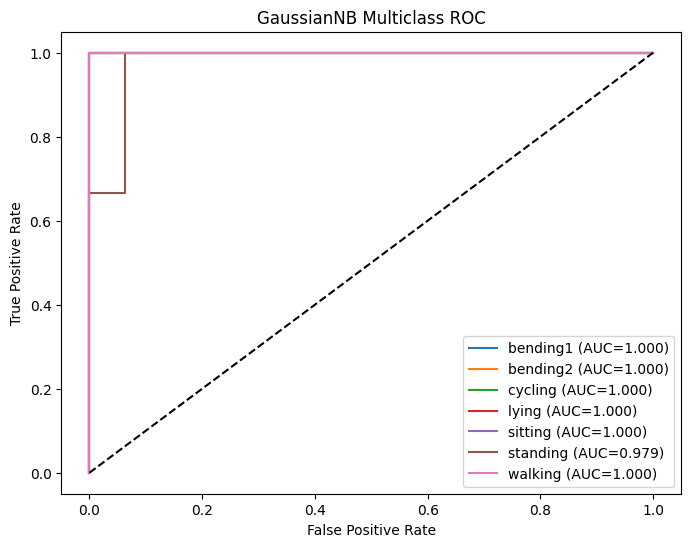

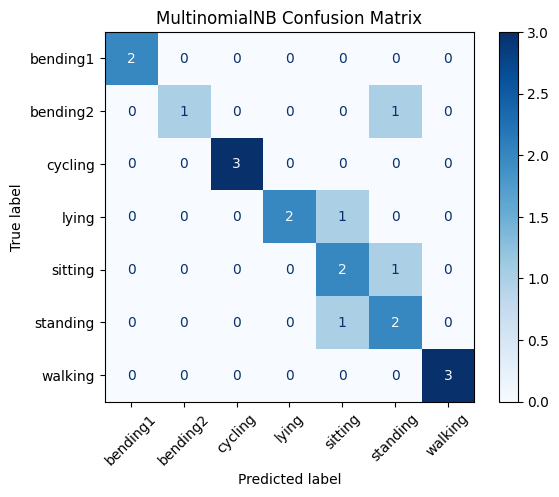

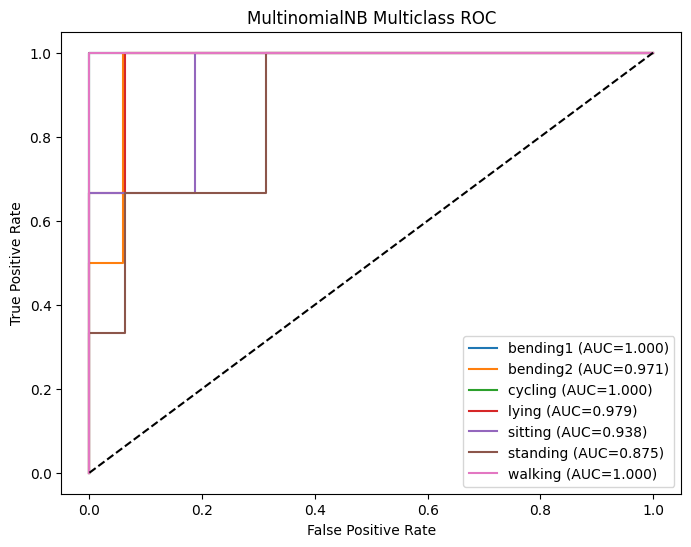

,Model,Best l,Test Accuracy,Test Error
0,GaussianNB,1,0.894737,0.105263
1,MultinomialNB,5,0.789474,0.210526


In [29]:
nb_test_results = []

for model_name, pipeline in nb_models.items():

    best_l_nb = int(
        best_nb_results.loc[
            best_nb_results["Model"] == model_name, "l"
        ].iloc[0]
    )

    X_train_nb, y_train_nb = extract_multiclass_features(
        train_data, best_l_nb
    )
    X_test_nb, y_test_nb = extract_multiclass_features(
        test_data, best_l_nb
    )

    X_test_nb = X_test_nb[X_train_nb.columns]

    pipeline.fit(X_train_nb, y_train_nb)

    y_pred_nb = pipeline.predict(X_test_nb)
    y_prob_nb = pipeline.predict_proba(X_test_nb)

    accuracy_nb = accuracy_score(y_test_nb, y_pred_nb)

    nb_test_results.append({
        "Model": model_name,
        "Best l": best_l_nb,
        "Test Accuracy": accuracy_nb,
        "Test Error": 1 - accuracy_nb
    })

    ConfusionMatrixDisplay.from_predictions(
        y_test_nb,
        y_pred_nb,
        labels=pipeline.classes_,
        xticks_rotation=45,
        cmap="Blues"
    )
    plt.title(f"{model_name} Confusion Matrix")
    plt.show()

    # Multiclass ROC
    classes_nb = pipeline.classes_
    y_bin_nb = label_binarize(y_test_nb, classes=classes_nb)

    plt.figure(figsize=(8, 6))

    for i, class_name in enumerate(classes_nb):
        if len(np.unique(y_bin_nb[:, i])) < 2:
            continue

        fpr, tpr, _ = roc_curve(
            y_bin_nb[:, i], y_prob_nb[:, i]
        )

        plt.plot(
            fpr, tpr,
            label=f"{class_name} (AUC={auc(fpr, tpr):.3f})"
        )

    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{model_name} Multiclass ROC")
    plt.legend()
    plt.show()

display(pd.DataFrame(nb_test_results))

Using stratified 5-fold cross-validation, GaussianNB achieved its best performance at \(l=1\) with a CV accuracy of 88.46%, while MultinomialNB performed best at \(l=5\) with a CV accuracy of 78.35%.

On the test set, GaussianNB achieved a lower error rate (**10.53%**) than MultinomialNB (**21.05%**). The confusion matrices and One-vs-Rest ROC curves also indicate better classification performance for GaussianNB, with fewer misclassifications and generally higher AUC values.

#### ii. Comparison

In [30]:
comparison_multi = pd.concat([
    pd.DataFrame([{
        "Model": "L1 Multinomial Logistic",
        "Best l": best_l_multi,
        "Test Accuracy": test_accuracy_multi,
        "Test Error": test_error_multi
    }]),
    pd.DataFrame(nb_test_results)
], ignore_index=True)

comparison_multi = comparison_multi.sort_values(
    "Test Error"
)

display(comparison_multi)

print(
    "Best model:",
    comparison_multi.iloc[0]["Model"]
)

,Model,Best l,Test Accuracy,Test Error
1,GaussianNB,1,0.894737,0.105263
0,L1 Multinomial Logistic,2,0.789474,0.210526
2,MultinomialNB,5,0.789474,0.210526


Best model: GaussianNB


GaussianNB performed best on the test set, achieving the lowest test error of **10.53%**, compared with 21.05% for both L1-penalized multinomial logistic regression and MultinomialNB. However, L1-penalized multinomial logistic regression achieved the highest cross-validation accuracy (92.86%), suggesting that its expected generalization performance may be competitive despite the higher observed test error.

## 3. ISLR 4.8.3

By Bayes' theorem, the Bayes classifier assigns an observation $x$ to the class that maximizes:

$$
P(Y=k \mid X=x) \propto \pi_k f_k(x)
$$

Since $X \mid Y=k \sim N(\mu_k,\sigma_k^2)$, the class-conditional density is:

$$
f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)
$$

Taking the logarithm and dropping the constant common to all classes, the discriminant function becomes:

$$
\delta_k(x)=\log\pi_k-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}
$$

Expanding the squared term:

$$
\delta_k(x)=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log\sigma_k+\log\pi_k
$$

Since the class-specific variances $\sigma_k^2$ are not assumed to be equal, the quadratic terms generally do not cancel when comparing discriminant functions. Therefore, the decision boundaries are determined by quadratic equations rather than linear equations.

In contrast, if all classes share the same variance, the quadratic terms cancel, resulting in linear discriminant functions, as in LDA.


## 4. ISLR 4.8.7

Given:

- $\mu_{\text{Yes}}=10$, $\mu_{\text{No}}=0$
- $\sigma^2=36$
- $P(Y=\text{Yes})=0.8$, $P(Y=\text{No})=0.2$
- $X=4$

By Bayes' theorem:

$$
P(Y=\text{Yes}\mid X=4)
=\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}
$$

Using the normal density function:

$$
f_{\text{Yes}}(4)=\frac{1}{6\sqrt{2\pi}}e^{-\frac{(4-10)^2}{72}}
=\frac{1}{6\sqrt{2\pi}}e^{-1/2}
$$

$$
f_{\text{No}}(4)=\frac{1}{6\sqrt{2\pi}}e^{-\frac{(4-0)^2}{72}}
=\frac{1}{6\sqrt{2\pi}}e^{-2/9}
$$

Substituting and canceling the common factor:

$$
P(Y=\text{Yes}\mid X=4)
=\frac{0.8e^{-1/2}}
{0.8e^{-1/2}+0.2e^{-2/9}}
\approx 0.752
$$

**Conclusion:** The predicted probability of issuing a dividend is approximately **75.2%**, so the company is classified as **Yes**.


## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9